**1. Импорт таблицы**

In [1]:
# %pip install matplotlib

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

BASE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = BASE / "data" / "samples"

In [3]:
df = pd.read_csv(DATA / "data_ai_assistant.csv", sep=';', low_memory=False)
df.head()

,request_id,instruction,intent,category,tags,response,property_type,property_id,has_typos,needs_escalation,...,source_label_method,additional_labels_method,annotation_status,weak_label_confidence,noise_type,scenario_group_id,policy_context,is_synthetic,property_assignment_method,category_ru
0,bitext_00001,"Чёрт возьми, не нахожу выставленные счета, пом...",invoices,BILLING,BCEIQWZ,Счета и чеки обычно доступны в личном кабинете...,hotel,NaN,1,0,...,source_intent,weak_rules_without_property_policies,requires_manual_review,0.35,missing_letter,bitext__invoices__29,unspecified,1,source_hospitality_hotel_only,счета
1,bitext_00002,"Не нахожу выставленные счета, помогите. Где мн...",invoices,BILLING,BCIPQZ,Счета и чеки обычно доступны в личном кабинете...,hotel,NaN,1,0,...,source_intent,weak_rules_without_property_policies,requires_manual_review,0.35,transposed_letters,bitext__invoices__29,unspecified,1,source_hospitality_hotel_only,счета
2,bitext_00003,Как скачать счета из личноо кабинета? Объяснит...,invoices,BILLING,BCILPQZ,Счета и чеки обычно доступны в личном кабинете...,hotel,NaN,1,0,...,source_intent,weak_rules_without_property_policies,requires_manual_review,0.35,missing_letter,bitext__invoices__44,unspecified,1,source_hospitality_hotel_only,счета
3,bitext_00004,"Да что же это таке, подскажите, как получить к...",invoices,BILLING,BCIPWZ,Счета и чеки обычно доступны в личном кабинете...,hotel,NaN,1,0,...,source_intent,weak_rules_without_property_policies,requires_manual_review,0.35,missing_letter,bitext__invoices__67,unspecified,1,source_hospitality_hotel_only,счета
4,bitext_00005,"Не нахожу выставленные счета, помогите. Что дл...",invoices,BILLING,BCILM,Счета и чеки обычно доступны в личном кабинете...,hotel,NaN,0,0,...,source_intent,weak_rules_without_property_policies,requires_manual_review,0.35,none,bitext__invoices__29,unspecified,1,source_hospitality_hotel_only,счета


**2. Основная информация**

*Описание датасета:*
- Датасет: data_ai_assistant.csv
- Тип: гибридный
- Количество объектов/строк: 35000
- Количество признаков/столбцов: 27

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 35000 entries, 0 to 34999
Data columns (total 27 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   request_id                  35000 non-null  str    
 1   instruction                 35000 non-null  str    
 2   intent                      35000 non-null  str    
 3   category                    35000 non-null  str    
 4   tags                        35000 non-null  str    
 5   response                    35000 non-null  str    
 6   property_type               35000 non-null  str    
 7   property_id                 0 non-null      float64
 8   has_typos                   35000 non-null  int64  
 9   needs_escalation            35000 non-null  int64  
 10  priority                    35000 non-null  str    
 11  language                    35000 non-null  str    
 12  source_dataset              35000 non-null  str    
 13  source_row_id               25000 non-null

*Описание полей:*
- **request_id** (`str`) — уникальный id записи вида bitext_N, где N = 00001..35000
- **instruction** (`str`) — текст обращения гостя на русском (после перевода)
- **intent** (`str`) — тип обращения, класс намерения; целевая метка классификатора
- **category** (`str`) — укрупнённая категория, группа интентов (грубее, чем intent)
- **tags** (`str`) — теги записи
- **response** (`str`) — ответ бота на это обращение (эталонный или сгенерированный)
- **property_type** (`str`) — тип объекта: apartment / hotel / guesthouse
- **has_typos** (`int64`) — бинарный флаг: есть ли в тексте опечатки (0/1)
- **needs_escalation** (`int64`) — целевая метка: 0 — бот отвечает сам, 1 — требуется человек
- **priority** (`str`) — приоритет обращения 
- **language** (`str`) — язык обращения (ожидается `ru` во всех строках)
- **source_dataset** (`str`) — исходный датасет, откуда взята строка
- **source_row_id** (`float64`) — id строки в исходном датасете; заполнено 25 000 из 35 000, `float64` — некорректный тип для идентификатора
- **original_instruction_en** (`str`) — исходный текст на английском до перевода; заполнено 25 000
- **original_response_en** (`str`) — исходный ответ на английском до перевода; заполнено 25 000
- **is_synthetic** (`int64`) — бинарный флаг: 1 — строка синтетическая, 0 — из реального источника

**Вывод:** Практически по всем столбцам полное заполнение для всех 35000 строк. 
Исключения: столбцы source_row_id, original_instruction_en, original_response_en, где заполнены 25000 строк. Это наши дополнительно добавленные 10000 строк сразу на русском языке.

**3. Анализ признаков**

**Текстовые признаки**

In [5]:
str_values = ['request_id', 'instruction', 'response']
for column in str_values:
    is_not_empty = df[column].astype(str).str.strip() != ''
    print(f"Количество корректных (заполненных) строк '{column}': {is_not_empty.sum()} из {df.shape[0]}")

Количество корректных (заполненных) строк 'request_id': 35000 из 35000
Количество корректных (заполненных) строк 'instruction': 35000 из 35000
Количество корректных (заполненных) строк 'response': 35000 из 35000


*Вывод:* Текстовые поля 'request_id', 'instruction', 'response' не содержат пропусков или пустых значений.
<br>
<br>
<br>

**Категориальные признаки**

- *Тип недвижимости 'property_type'*

Возможные значения:

In [6]:
df['property_type'].unique()

<StringArray>
['hotel', 'apartment', 'guesthouse']
Length: 3, dtype: str

Сумма по группам:

In [7]:
print("сумма групп:", df.groupby("property_type").size().sum())
vc = df["property_type"].value_counts()
pd.DataFrame({
    "кол-во, шт": vc,
    "доля, %": (vc / vc.sum() * 100).round(1),
})

сумма групп: 35000


,"кол-во, шт","доля, %"
property_type,,
hotel,28430,81.2
guesthouse,3484,10.0
apartment,3086,8.8


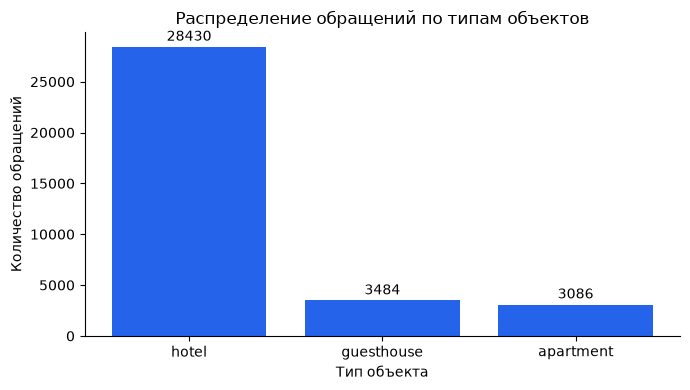

In [8]:
counts = df["property_type"].value_counts()   # уже отсортировано по убыванию

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(counts.index, counts.values, color="#2563EB")
ax.bar_label(bars, fmt="%d", padding=2)        # числа над столбиками

ax.set_title("Распределение обращений по типам объектов")
ax.set_xlabel("Тип объекта")
ax.set_ylabel("Количество обращений")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

Доля исходных обращений для разных типов недвижимости:

In [9]:
g = df.groupby("property_type")["original_instruction_en"].agg(
    total="size",
    is_origin="count",
)
g["is_added"] = g["total"] - g["is_origin"]
print(g)

               total  is_origin  is_added
property_type                            
apartment       3086          0      3086
guesthouse      3484          0      3484
hotel          28430      25000      3430


*Вывод:* Имеется три типа недвижимости 'hotel', 'apartment', 'guesthouse'. Мы видим,  что 81% обращений относятся к отелям, что не отражает реальную структуру рынка краткосрочной аренды, а является следствием формирования датасета, который изначально формировался под отели и куда мы искусственно добавили дополнительные обращения для всех 3 типов недвижимости. Способ устранения дисбаланса рассмотрим на этапе обучения.
<br>
<br>

- *Категории 'category' и интенты 'intent'*

Все возможные значения категорий:

In [10]:
df['category'].unique()

<StringArray>
[          'BILLING', 'CANCELLATION_FEES',          'CHECK_IN',
         'CHECK_OUT',           'CONTACT',             'EVENT',
          'FEEDBACK',             'HOTEL',           'LUGGAGE',
              'MENU',             'NIGHT',     'PARKING_SPACE',
              'PETS',            'POINTS',            'REFUND',
   'SHUTTLE_SERVICE',    'GUEST_SERVICES',           'BOOKING',
       'MAINTENANCE',         'COMPLAINT',         'DEPARTURE',
       'HOUSE_RULES',           'ARRIVAL',        'FACILITIES',
      'HOUSEKEEPING',            'ACCESS',            'SAFETY',
       'LOCAL_GUIDE',     'ACCESSIBILITY']
Length: 29, dtype: str

<br>
Все возможные значения интентов:

In [11]:
df['intent'].unique()

<StringArray>
[                'invoices',        'cancellation_fees',
                 'check_in',                'check_out',
         'customer_service',              'human_agent',
               'host_event',           'file_complaint',
             'leave_review',               'book_hotel',
 'cancel_hotel_reservation', 'change_hotel_reservation',
   'check_hotel_facilities',       'check_hotel_offers',
       'check_hotel_prices',  'check_hotel_reservation',
             'search_hotel',            'store_luggage',
               'check_menu',                'add_night',
       'book_parking_space',               'bring_pets',
            'redeem_points',               'get_refund',
          'shuttle_service',            'lost_property',
             'extra_guests',             'wifi_problem',
          'noise_complaint',             'power_outage',
   'late_check_out_request',           'pest_complaint',
            'visitor_rules', 'air_conditioning_problem',
   'early_check_i

<br>
Интенты, сгруппированные по категориям, в порядке убывания:

In [12]:
categorized_total = 0
for cat in df["category"].value_counts().index:
    g = df[df["category"] == cat]
    print(f"\n{cat}  ({len(g)}, {len(g)/len(df):.2%})")
    for intent, n in g["intent"].value_counts().items():
        categorized_total += n
        print(f"   {intent:26s} {n:5d}")
print(f"\nВсего строк с корректными интентами/категориями: {categorized_total}")


HOTEL  (8969, 25.63%)
   check_hotel_facilities      1136
   check_hotel_offers          1126
   check_hotel_prices          1126
   change_hotel_reservation    1122
   cancel_hotel_reservation    1120
   search_hotel                1120
   book_hotel                  1110
   check_hotel_reservation     1109

CONTACT  (2259, 6.45%)
   customer_service            1131
   human_agent                 1128

FEEDBACK  (2214, 6.33%)
   file_complaint              1109
   leave_review                1105

PARKING_SPACE  (1509, 4.31%)
   book_parking_space          1114
   parking_problem              198
   parking_information          197

BILLING  (1324, 3.78%)
   invoices                    1125
   billing_dispute              199

MAINTENANCE  (1283, 3.67%)
   access_problem               204
   air_conditioning_problem     197
   appliance_problem            194
   wifi_problem                 193
   water_problem                191
   heating_problem              176
   power_outage   

In [13]:
chk = df.groupby("intent", dropna=False)["category"].agg(
    строк="size",
    категорий=lambda s: s.dropna().astype(str).str.strip().replace("", pd.NA).dropna().nunique(),
    какие=lambda s: ", ".join(sorted(s.dropna().astype(str).str.strip().unique())),
)
chk = chk.sort_values("категорий", ascending=False)

print(chk)
print()
print("интентов без категории      :", (chk["категорий"] == 0).sum())
print("интентов с >1 категорией    :", (chk["категорий"] > 1).sum())
print("строк с пустой категорией   :",
      df["category"].isna().sum() + (df["category"].astype(str).str.strip() == "").sum())

                        строк  категорий        какие
intent                                               
access_problem            204          1  MAINTENANCE
pet_issue                 182          1    COMPLAINT
kitchen_usage             188          1   FACILITIES
late_check_out_request    199          1    DEPARTURE
laundry_information       196          1   FACILITIES
...                       ...        ...          ...
early_check_in_request    173          1      ARRIVAL
extra_guests              201          1      BOOKING
file_complaint           1109          1     FEEDBACK
get_refund               1113          1       REFUND
wifi_problem              193          1  MAINTENANCE

[63 rows x 3 columns]

интентов без категории      : 0
интентов с >1 категорией    : 0
строк с пустой категорией   : 0


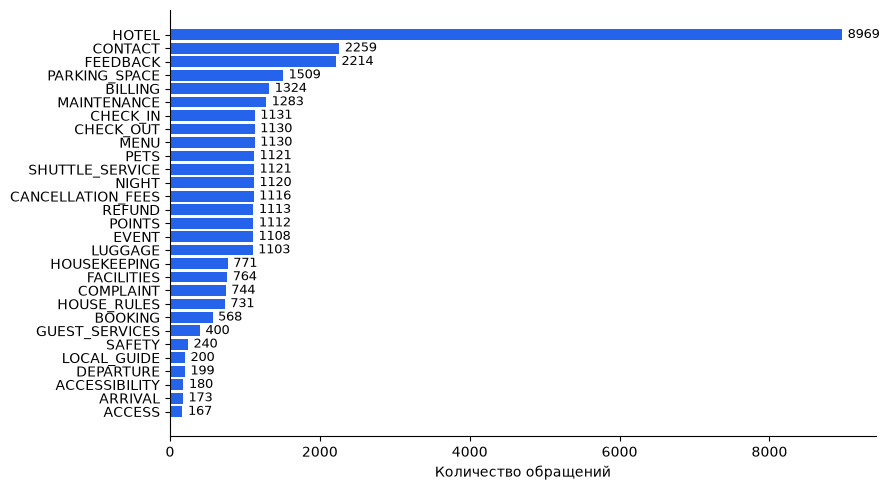

In [14]:
cat = df["category"].value_counts()
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(cat.index[::-1], cat.values[::-1], color="#2563EB")

ax.bar_label(bars, fmt="%d", padding=4, fontsize=9)
ax.set_xlabel("Количество обращений")
ax.set_ylabel("")
ax.tick_params(labelsize=10)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

Самые популярные категории обращений по типам проживания:

In [15]:
for prop, sub in df.groupby("property_type", dropna=False):
    vc = sub["category"].value_counts(normalize=True).mul(100)
    t = (vc.head(3).to_frame("доля, %").assign(шт=sub["category"].value_counts().head(3)))
    print(f"\n{prop}  ({len(sub)} строк)")
    print(t.round(1).to_string())
    print()


apartment  (3086 строк)
             доля, %   шт
category                 
MAINTENANCE     13.5  416
HOTEL           10.4  321
FACILITIES       9.1  282


guesthouse  (3484 строк)
             доля, %   шт
category                 
MAINTENANCE     12.5  436
HOTEL            9.1  316
FACILITIES       8.0  277


hotel  (28430 строк)
          доля, %    шт
category               
HOTEL        29.3  8332
CONTACT       7.3  2071
FEEDBACK      7.3  2064



Доля категории HOTEL для всех обращений:

In [16]:
n = (df["category"].astype(str).str.strip().str.lower() == "hotel").sum()
print(f"{n:,} из {len(df):,} = {n / len(df):.1%}")

8,969 из 35,000 = 25.6%


*Вывод:* После проверки столбцов 'category', 'intent' мы видим, что данные корректные. Нет интентов без категории и нет пустых категорий, значения присутствуют в каждой строке. Можно заметить, что обращения с категорией Hotel самые многочисленные в целом (25.6%) и в категории отелей (29%). Лидерство категории объясняется двумя причинами: составом выборки (81% записей — отели) и устойчивой связью темы с типом объекта.
<br>
<br>

- *Приоритет обращения 'priority'*

Возможные значения:

In [17]:
df['priority'].unique()

<StringArray>
['low', 'medium', 'high', 'critical']
Length: 4, dtype: str

In [18]:
df["priority"].value_counts(dropna=False)

priority
low         23435
medium       9313
high         1965
critical      287
Name: count, dtype: int64

Категории с самой большой долей обращений с приоритетом Critical:

In [19]:
raw = pd.crosstab(df["category"], df["priority"]).reindex(columns=["critical"], fill_value=0)
keep = raw["critical"] > 0

c = pd.crosstab(df["category"], df["priority"], normalize="index").mul(100).round(1)
print(c.loc[keep, ["critical"]].sort_values("critical", ascending=False))

priority     critical
category             
SAFETY           96.2
MAINTENANCE       4.4


Доля обращений с приоритетом critical среди интентов по убыванию:

In [20]:
t = pd.crosstab(df["intent"], df["priority"])
t["всего"] = t.sum(axis=1)
t["critical, %"] = (t["critical"] / t["всего"] * 100).round(1)
print(
    t[t["critical"] > 0]  
    .sort_values("critical, %", ascending=False)[["critical", "всего", "critical, %"]]
    .to_string()
)

priority           critical  всего  critical, %
intent                                         
medical_emergency       107    107        100.0
safety_incident         124    133         93.2
power_outage             56    128         43.8


Распределение приоритетов среди категорий:

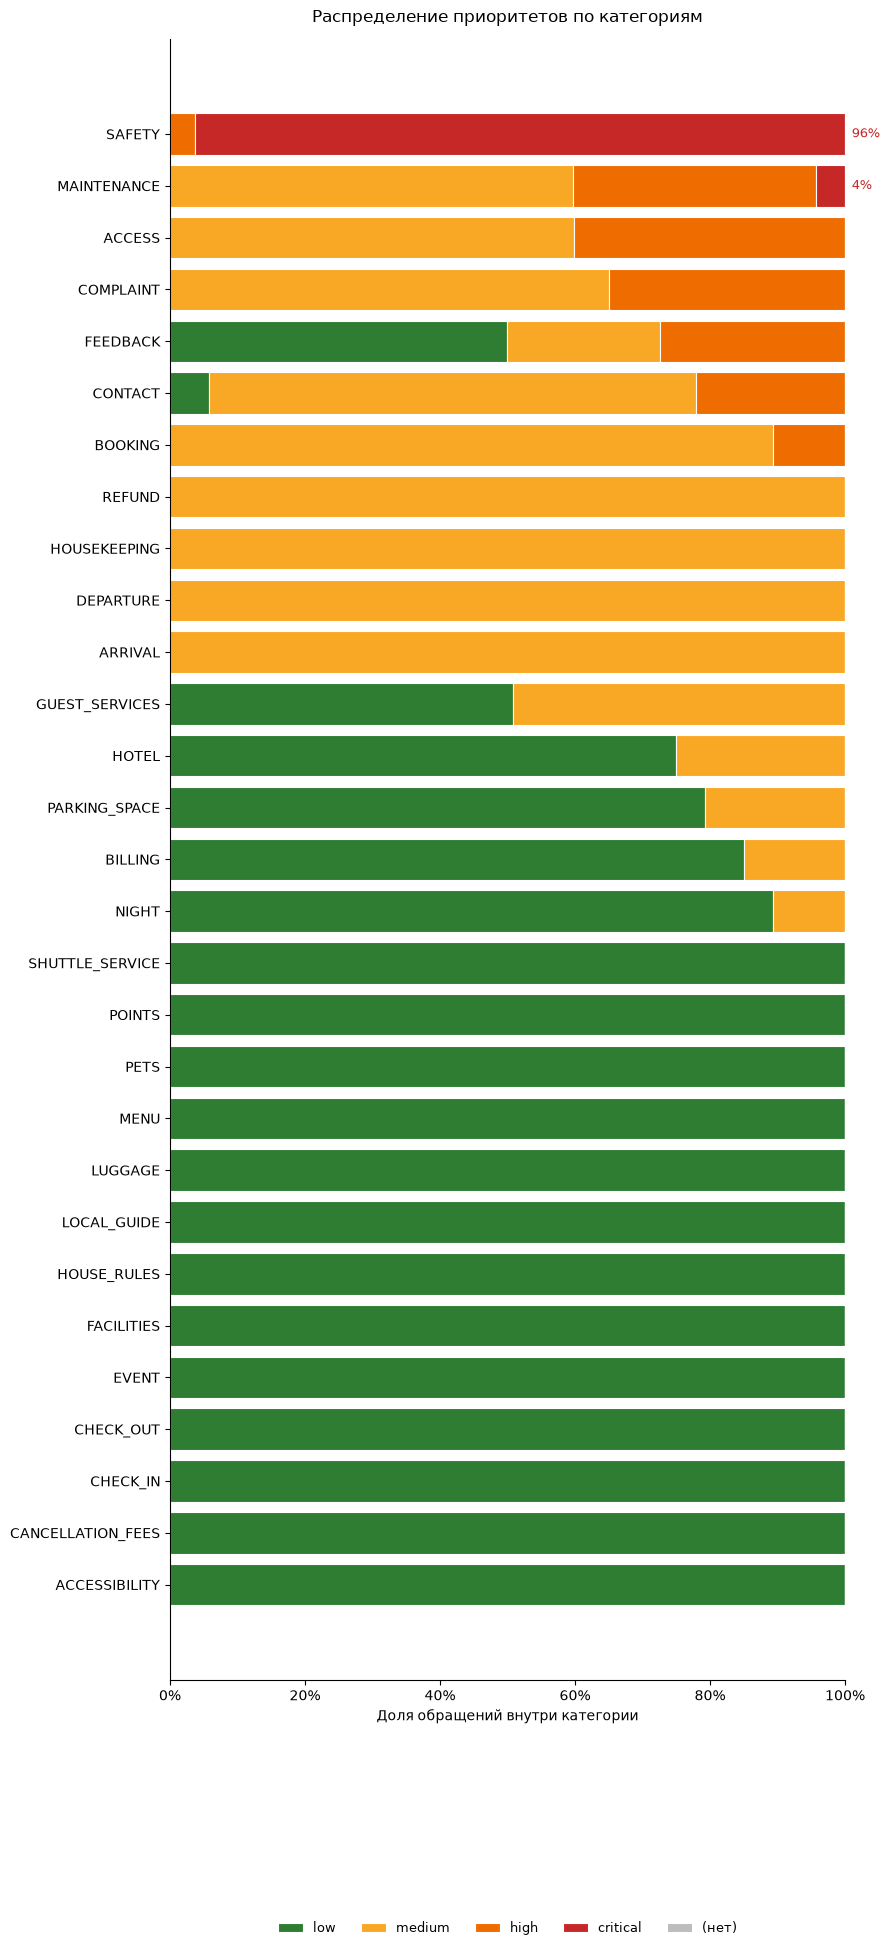

In [21]:
order  = ["low", "medium", "high", "critical", "(нет)"]
colors = {"low":      "#2E7D32",
          "medium":   "#F9A825",
          "high":     "#EF6C00",
          "critical": "#C62828",
          "(нет)":    "#BDBDBD"}

sub = df.copy()
sub["priority"] = sub["priority"].fillna("(нет)")

share = pd.crosstab(sub["category"], sub["priority"]).reindex(columns=order, fill_value=0)
share = share.div(share.sum(axis=1), axis=0)

share = share.sort_values(
    ["critical", "high", "medium", "low", "(нет)"],
    ascending=[True, True, True, True, False],
)

fig, ax = plt.subplots(figsize=(9, 0.6 * len(share) + 2))
left = np.zeros(len(share))

for p in order:
    ax.barh(share.index, share[p], left=left, color=colors[p],
            label=p, edgecolor="white", linewidth=0.8)
    left += share[p].values

for y, v in enumerate(share["critical"]):
    if v > 0:
        ax.text(1.01, y, f"{v:.0%}", va="center", fontsize=9, color=colors["critical"])

ax.set_xlim(0, 1)
ax.set_xlabel("Доля обращений внутри категории")
ax.set_title("Распределение приоритетов по категориям", pad=12)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
ax.tick_params(labelsize=10)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.14),
          frameon=False, fontsize=9)

plt.tight_layout()
plt.show()

*Вывод:* Столбец 'priority' содержит 4 значения приоритетов обращений от critical к low. Основная масса обращений имеет самый низкий приоритет. Так же определены категории, где высокая доля обращений с самым высоким приоритетом, это SAFETY (Безопасность) и MAINTENANCE (Обслуживание). В интентах категории SAFETY доля critical обращений стремится к 100%.
На графике можно увидеть распределение приоритетов внутри категорий. Мы видим, что вопросы безопасности, обслуживания, доступа, жалобы имеют высокий приоритет, в то время как вопросы, касающиеся стандартных тем типа заселения, багажа, а так же дополнительные услуги типа меню, размещения с питомцами имеют низкий приоритет.
<br>
<br>

**Бинарные признаки**

- *Наличие опечаток 'has_typos'*
- *Целевая переменная: Решение об эскалации 'needs_escalation'*

In [22]:
bins = ["has_typos", "needs_escalation"]

for c in bins:
    vc = df[c].value_counts(dropna=False)
    print(f"{c:18s} {vc.to_dict()}   доля 1: {df[c].mean():.1%}")

has_typos          {0: 21836, 1: 13164}   доля 1: 37.6%
needs_escalation   {1: 18446, 0: 16554}   доля 1: 52.7%


*Вывод:* Столбцы 'has_typos' и 'needs_escalation' принимают значения 0 и 1. Пустых значений нет, так же нет некорректных значений. Баланс нормальный. По балансу можно сделать вывод, что доля эскалаций больше половины, а значит продукт смог бы сэнонмить владельцу всего половину работы.

**Выводы:**

**1. Данные.** 35 000 записей: 25 000 переведены с английского, 10 000 изначально на русском. Пропусков и пустых значений в содержательных колонках нет, дубликатов не обнаружено. Происхождение каждой записи зафиксировано, что позволяет считать метрики раздельно.

**2. Типы объектов.** 81% записей — отели, по 9–10% квартиры и гостевые дома. Это следствие формирования датасета, а не структуры рынка краткосрочной аренды. Отсюда два обязательных решения: стратификация train/test по типу объекта и раздельные метрики по каждому типу.

**3. Метки корректны.** У каждого интента ровно одна категория, пустых значений нет. Категория `HOTEL` лидирует по двум причинам: отелей численно больше, и внутри отелей эта тема тоже доминирует — то есть её популярность не объясняется только размером группы.

**4. Приоритеты осмысленны.** Четыре уровня от `low` до `critical`, шкала используется полностью. `critical` сосредоточен в категориях `SAFETY` и `MAINTENANCE`, спокойные темы (заселение, багаж, доп. услуги) высокого приоритета не получают — это соответствует политике.

**5. Эскалация — главная проблема продукта.** Метка сбалансирована (52/48), но 52% эскалаций означают, что консьерж закрывает меньше половины обращений. Целевой уровень для такого продукта — 15–25%. Нужна ревизия разметки: вероятно, часть обращений с ответом в базе знаний помечена как требующая человека.

## Часть 2 Исследовательский анализ эскалаций

### Подготовка данных и контроль целевых меток


На первом этапе необходимо проверить, что признаки, используемые для анализа эскалации и приоритетов, имеют корректные типы и допустимые значения.

В датасете используются две целевые переменные: needs_escalation — бинарный признак необходимости передачи обращения сотруднику, и priority — порядковая категориальная переменная, характеризующая срочность реагирования.

Для сохранения воспроизводимости создадим отдельную копию исходного датасета.

In [24]:
import seaborn as sns

In [25]:
RANDOM_STATE = 42

PRIORITY_ORDER = ["low","medium","high","critical"]
sns.set_theme(style="whitegrid")
eda = df.copy(deep=True)

required_columns = {"request_id","instruction","intent","category","property_type","priority","needs_escalation","has_typos","scenario_group_id","annotation_status"}
missing = required_columns - set(eda.columns)
assert not missing, f"Отсутствующие колонки: {missing}"
assert eda["request_id"].is_unique

for col in ["needs_escalation", "has_typos"]:
    eda[col] = pd.to_numeric(eda[col],errors="raise").astype("int8")

eda["priority"] = (eda["priority"].astype("string").str.strip().str.lower())

assert eda["needs_escalation"].isin([0, 1]).all()
assert eda["has_typos"].isin([0, 1]).all()
assert eda["priority"].isin(PRIORITY_ORDER).all()

eda["word_count"] = (eda["instruction"].fillna("").str.findall(r"(?u)\b\w+\b").str.len())

print("Количество обращений:", len(eda))
print("Количество намерений:", eda["intent"].nunique())
print("Количество сценарных групп:", eda["scenario_group_id"].nunique())

print("\nКонтроль пропусков:")
display(eda[["intent", "priority", "needs_escalation"]].isna().sum())

Количество обращений: 35000
Количество намерений: 63
Количество сценарных групп: 902

Контроль пропусков:


intent              0
priority            0
needs_escalation    0
dtype: int64

Проверка подтвердила наличие 35 000 обращений, распределённых между 63 намерениями и 902 сценарными группами. Признаки эскалации и наличия опечаток имеют допустимые бинарные значения, а переменная приоритета принимает четыре значения: low, medium, high, critical.

Пропуски в рассматриваемых целевых полях отсутствуют.

Таким образом, данные технически согласованы и допускают применение методов описательной статистики и анализа категориальных зависимостей.

### Зависимость эскалации от намерения пользователя

Одной из основных гипотез проекта является предположение о том, что необходимость эскалации связана с характером пользовательского запроса.

В зависимости от намерения AI-консьерж может предоставлять информационный ответ, выполнять разрешённое действие или передавать обращение сотруднику. Поэтому необходимо установить, как распределяется доля эскалаций между различными intent.

Для каждого намерения рассчитаем количество обращений, число эскалаций и относительную долю needs_escalation = 1.

Дополнительно используем 95%-е интервалы Уилсона. Они позволяют учитывать различия в объёме наблюдений и корректнее отражают неопределённость пропорций, особенно когда наблюдаемая доля близка к нулю или единице.

In [26]:
intent_stats = (eda.groupby("intent").agg(n=("request_id", "size"),n_escalations=("needs_escalation", "sum")))
intent_stats["rate"] = (intent_stats["n_escalations"]/ intent_stats["n"])
z = 1.959963984540054 #интервал Уилсона

n = intent_stats["n"].to_numpy(dtype=float)
p = intent_stats["rate"].to_numpy(dtype=float)

denominator = 1 + z**2 / n
center = (p + z**2 / (2 * n)) / denominator
half_width = (z / denominator* np.sqrt(p * (1 - p) / n+ z**2 / (4 * n**2)))
intent_stats["ci_lower"] = np.clip(center - half_width, 0, 1)
intent_stats["ci_upper"] = np.clip(center + half_width, 0, 1)

top_names = (eda["intent"].value_counts().head(15).index)
top = (intent_stats.loc[top_names].sort_values("rate").copy())

left_error = np.maximum(top["rate"] - top["ci_lower"],0.0).to_numpy(dtype=float)
right_error = np.maximum(top["ci_upper"] - top["rate"],0.0).to_numpy(dtype=float)

xerr = np.vstack([left_error, right_error])

assert np.isfinite(xerr).all()
assert (xerr >= 0).all()

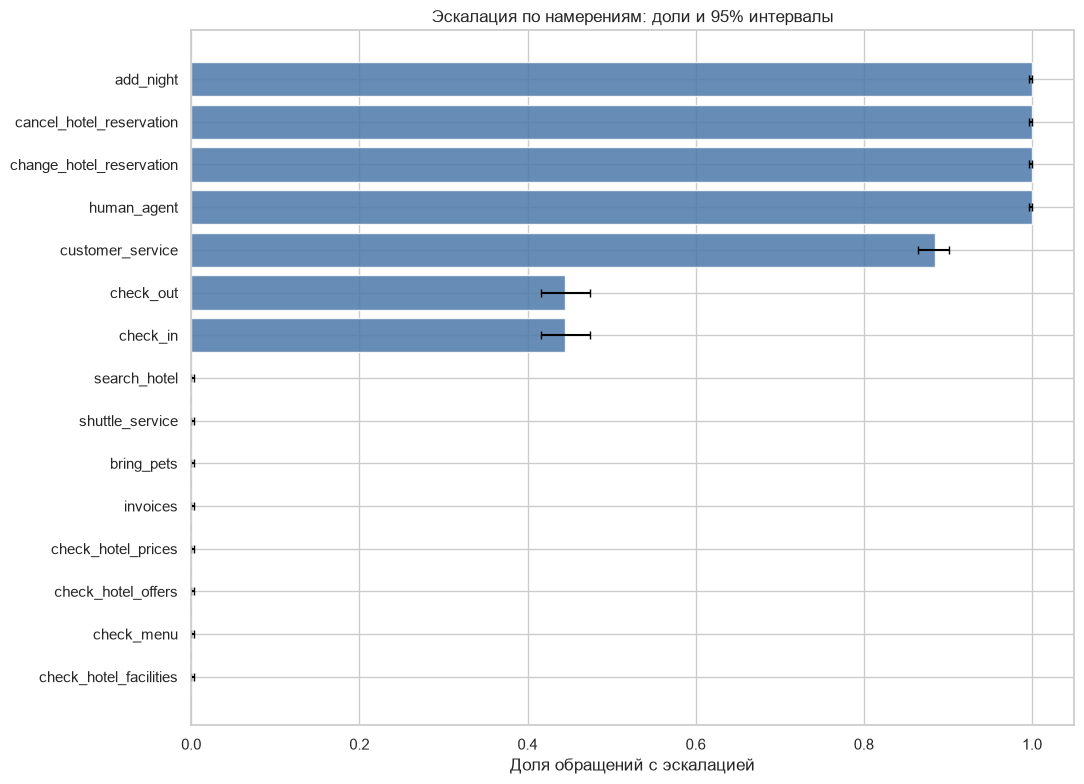

,n,n_escalations,rate,ci_lower,ci_upper
intent,,,,,
access_problem,204,204,1.0,0.9815,1.0000
cleaning_request,199,199,1.0,0.9811,1.0000
extra_guests,201,201,1.0,0.9812,1.0000
file_complaint,1109,1109,1.0,0.9965,1.0000
get_refund,1113,1113,1.0,0.9966,1.0000
...,...,...,...,...,...
local_recommendation,200,0,0.0,0.0000,0.0188
check_hotel_facilities,1136,0,0.0,0.0000,0.0034
leave_review,1105,0,0.0,0.0000,0.0035


In [27]:
fig, ax = plt.subplots(figsize=(11, 8))
y = np.arange(len(top))
ax.barh(y,top["rate"],color="#4C78A8",alpha=0.85)
ax.errorbar(x=top["rate"].to_numpy(),y=y,xerr=xerr,fmt="none",ecolor="black",capsize=3)
ax.set_yticks(y)
ax.set_yticklabels(top.index)
ax.set_xlim(0, 1.05)
ax.set_xlabel("Доля обращений с эскалацией")
ax.set_title("Эскалация по намерениям: доли и 95% интервалы")
plt.tight_layout()
plt.show()

display(intent_stats.sort_values("rate", ascending=False).round(4))

Анализируя полученный график можно заметить существенную неоднородность долей эскалации между намерениями.
Это означает, что в текущей структуре разметки необходимость эскалации в значительной степени определяется самим намерением пользователя.

Например, запросы на изменение бронирования и обращения, требующие участия оператора, имеют высокую частоту передачи сотруднику. Напротив, отдельные информационные намерения полностью представлены обращениями без эскалации.

С практической точки зрения результат показывает, что распознавание намерения может стать важным этапом определения дальнейшего маршрута обработки обращения.


### Количественная оценка зависимости меток от intent

Здесь попытаемся исследовать , какая доля целевых значений может быть восстановлена исключительно по наиболее распространённой метке внутри каждого намерения.

Данная оценка позволит установить, насколько дополнительная информация о намерении повышает согласованность предсказаний с имеющейся разметкой.


In [28]:
def majority_agreement(data, feature, target):
    table = pd.crosstab(data[feature],data[target])
    majority_count = (table.max(axis=1).sum())

    return majority_count / len(data)


results = []

for target in ["needs_escalation", "priority"]:
    global_baseline = (eda[target].value_counts(normalize=True).max())
    intent_agreement = majority_agreement(eda,"intent",target)
    results.append({
        "Target": target,
        "Global baseline": global_baseline,
        "Intent majority": intent_agreement,
        "Difference": (intent_agreement - global_baseline)
    })

agreement_df = pd.DataFrame(results)
display(agreement_df.round(4))

,Target,Global baseline,Intent majority,Difference
0,needs_escalation,0.5270,0.9516,0.4245
1,priority,0.6696,0.9494,0.2798


Предоставленные резуальтаты демонситруют существенную дополнительную информацию, содержащуюся в метке намерения.

Для эскалации переход от глобального большинства к учёту intent повышает согласованность с разметкой на 42,45 процентного пункта. А для приоритета прирост составляет 27,98 процентного пункта. Следовательно, обе целевые переменные обладают выраженной зависимостью от типа пользовательского запроса.

Это дает нам два следсвия для ML:
 - распознавание намерения может быть полезным компонентом системы маршрутизации обращений и определения срочности;
 - классификаторы эскалации и приоритета могут показывать высокую согласованность с текущими метками, используя преимущественно информацию о intent, без глубокого анализа конкретной ситуации.

### Совместный анализ эскалации и приоритета

Так как эскалация и приоритет описывают разные характеристики обращения, то здесь важно определить, насколько независимо представлены эти признаки и какие сочетания решений встречаются в корпусе.

Для этого построим таблицу сопряжённости и условное распределение эскалаций по уровням приоритета.

In [29]:
priority_esc = pd.crosstab(eda["priority"],eda["needs_escalation"]).reindex(index=PRIORITY_ORDER,columns=[0, 1],fill_value=0)
display(priority_esc)
priority_esc_pct = (priority_esc.div(priority_esc.sum(axis=1), axis=0).mul(100))

needs_escalation,0,1
priority,,
low,16554,6881
medium,0,9313
high,0,1965
critical,0,287


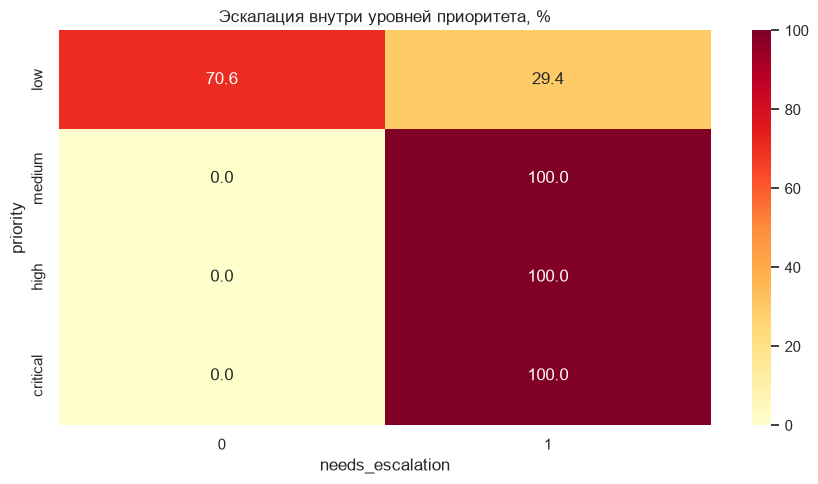

Всего обращений с эскалацией: 18446
Обращений low с эскалацией: 6881


In [ ]:
plt.figure(figsize=(9, 5))
sns.heatmap(priority_esc_pct,annot=True,fmt=".1f",cmap="YlOrRd",vmin=0,vmax=100)
plt.title("Эскалация внутри уровней приоритета, %")
plt.xlabel("needs_escalation")
plt.ylabel("priority")
plt.tight_layout()
plt.show()
print("Всего обращений с эскалацией:",int(eda["needs_escalation"].sum()))
print("Обращений low с эскалацией:",int(priority_esc.loc["low", 1]))

приоритет и эскалация являются связанными, но содержательно различными целевыми переменными. При разработке ML-системы целесообразно рассматривать их как отдельные задачи, а найденную зависимость учитывать при проектировании совместной логики принятия решений.

### Статистическая связь эскалации с категориальными признаками

Для определения факторов, наиболее тесно связанных с эскалацией, необходимо сравнить силу статистической ассоциации различных категориальных признаков с целевой переменной.

Использутся коэффициент V Крамера, основанный на статистике критерия хи-квадрат.

In [31]:
from scipy.stats import chi2_contingency

In [32]:
def cramers_v(x, y):
    table = pd.crosstab(x, y)
    if min(table.shape) < 2:
        return np.nan
    chi2 = chi2_contingency(table,correction=False).statistic
    n = table.to_numpy().sum()
    value = np.sqrt(chi2 / (n * min(table.shape[0] - 1,table.shape[1] - 1)))

    return float(value)


feature_pairs = [
    ("intent", "needs_escalation"),
    ("category", "needs_escalation"),
    ("priority", "needs_escalation"),
    ("property_type", "needs_escalation"),
    ("has_typos", "needs_escalation"),
    ("intent", "priority")
]

association_results = []
for feature_1, feature_2 in feature_pairs:
    association_results.append({"Feature 1": feature_1,"Feature 2": feature_2,"Cramers V": cramers_v(eda[feature_1],eda[feature_2])})
association_df = (pd.DataFrame(association_results).sort_values("Cramers V", ascending=False))
display(association_df.round(4))

,Feature 1,Feature 2,Cramers V
0,intent,needs_escalation,0.9316
5,intent,priority,0.8785
1,category,needs_escalation,0.7261
2,priority,needs_escalation,0.6655
3,property_type,needs_escalation,0.0304
4,has_typos,needs_escalation,0.0150


Наиболее выраженная связь эскалации наблюдается с намерением пользователя. Коэффициент V Крамера составляет 0,9316, что указывает на очень сильную ассоциацию.

Укрупнённая категория также связана с эскалацией, однако слабее, чем более детализированное намерение. Это согласуется с иерархической структурой признаков, при которой одна категория включает несколько различных сценариев обращения.

### Эскалация и тип объекта размещения: контроль неоднородности выборки

AI-консьерж проектируется как универсальная система для отелей, квартир краткосрочного проживания и гостевых домов. При этом правила обработки обращений могут существенно различаться между объектами. Для более сопоставимого исследования выделим часть корпуса, в которой представлены все три типа объектов, и оценим распределение эскалаций внутри неё.

In [33]:
eda_types = eda.loc[eda["source_dataset"] == "team_generated_ru_v2"].copy()
property_stats = (eda_types.groupby("property_type").agg(
        n=("request_id", "size"),
        n_escalations=("needs_escalation", "sum"),
        escalation_rate=("needs_escalation", "mean"),
        n_intents=("intent", "nunique")
    )
)
display(property_stats.round(4))

,n,n_escalations,escalation_rate,n_intents
property_type,,,,
apartment,3086,1756,0.5690,57
guesthouse,3484,1903,0.5462,62
hotel,3430,1906,0.5557,62


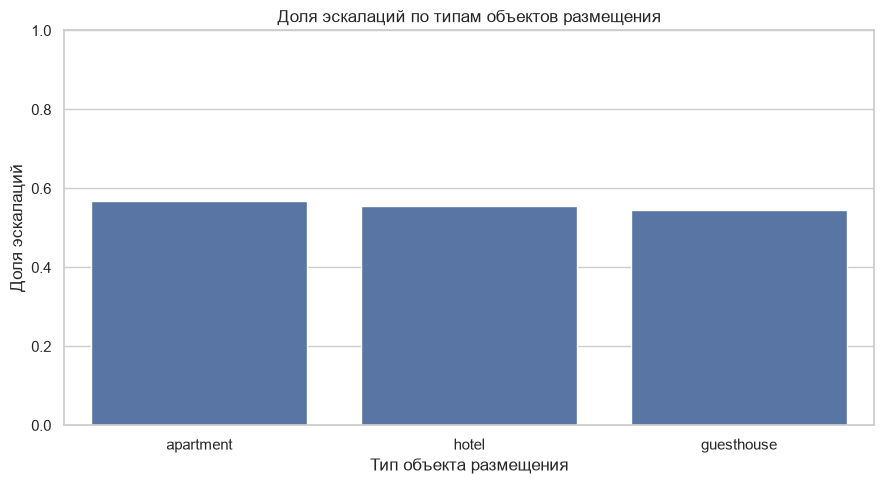

In [34]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=eda_types,x="property_type",y="needs_escalation",errorbar=None,ax=ax)
ax.set_ylim(0, 1)
ax.set_title("Доля эскалаций по типам объектов размещения")
ax.set_xlabel("Тип объекта размещения")
ax.set_ylabel("Доля эскалаций")
plt.tight_layout()
plt.show()

In [35]:
# Проверяем разнообразие решений внутри intent
intent_variability = (eda_types.groupby("intent")["needs_escalation"].nunique())
print("Интентов с несколькими значениями эскалации:",int((intent_variability > 1).sum()))
print("Интентов с постоянной меткой:",int((intent_variability == 1).sum()))

Интентов с несколькими значениями эскалации: 0
Интентов с постоянной меткой: 63


В рассматриваемой части корпуса доли эскалаций находятся в сравнительно узком диапазоне — от 54,62% до 56,90%. С одной стороны это указывает на сходство распределений решений для трёх типов объектов. Однако дополнительный анализ выявил принципиальное ограничение: у всех 63 намерений внутри этой выборки метка эскалации постоянна.

Таким образом различия долей эскалаций между типами объектов объясняются прежде всего различиями в представленности намерений. Данные не содержат достаточной вариативности для исследования того, как тип объекта изменяет решение при фиксированном намерении.

А в разработке это особенно важно для архитектуры универсального AI-консьержа.Так как решение об эскалации должно определяться не общей категорией «отель» или «квартира», а правилами конкретного объекта и обстоятельствами обращения.

## Часть 3. Углублённый анализ приоритетов

### Вариативность приоритета внутри намерений

Для автоматической приоритизации обращений необходимо установить, насколько уровень срочности зависит от типа запроса и насколько он изменяется в пределах одного намерения.

Если каждому intent соответствует фиксированный приоритет, то задача модели фактически сводится к определению намерения и последующему сопоставлению его с заранее заданным уровнем срочности.

Такая схема может быть полезна для простой маршрутизации, однако не обеспечивает полноценную оценку обстоятельств обращения.

In [36]:
priority_variability = (eda.groupby("intent")["priority"].nunique())
display(priority_variability.value_counts().sort_index().to_frame("Количество намерений"))
n_single_priority = int((priority_variability == 1).sum())
print("Интентов с одним приоритетом:",n_single_priority)

,Количество намерений
priority,
1,50
2,13


Интентов с одним приоритетом: 50


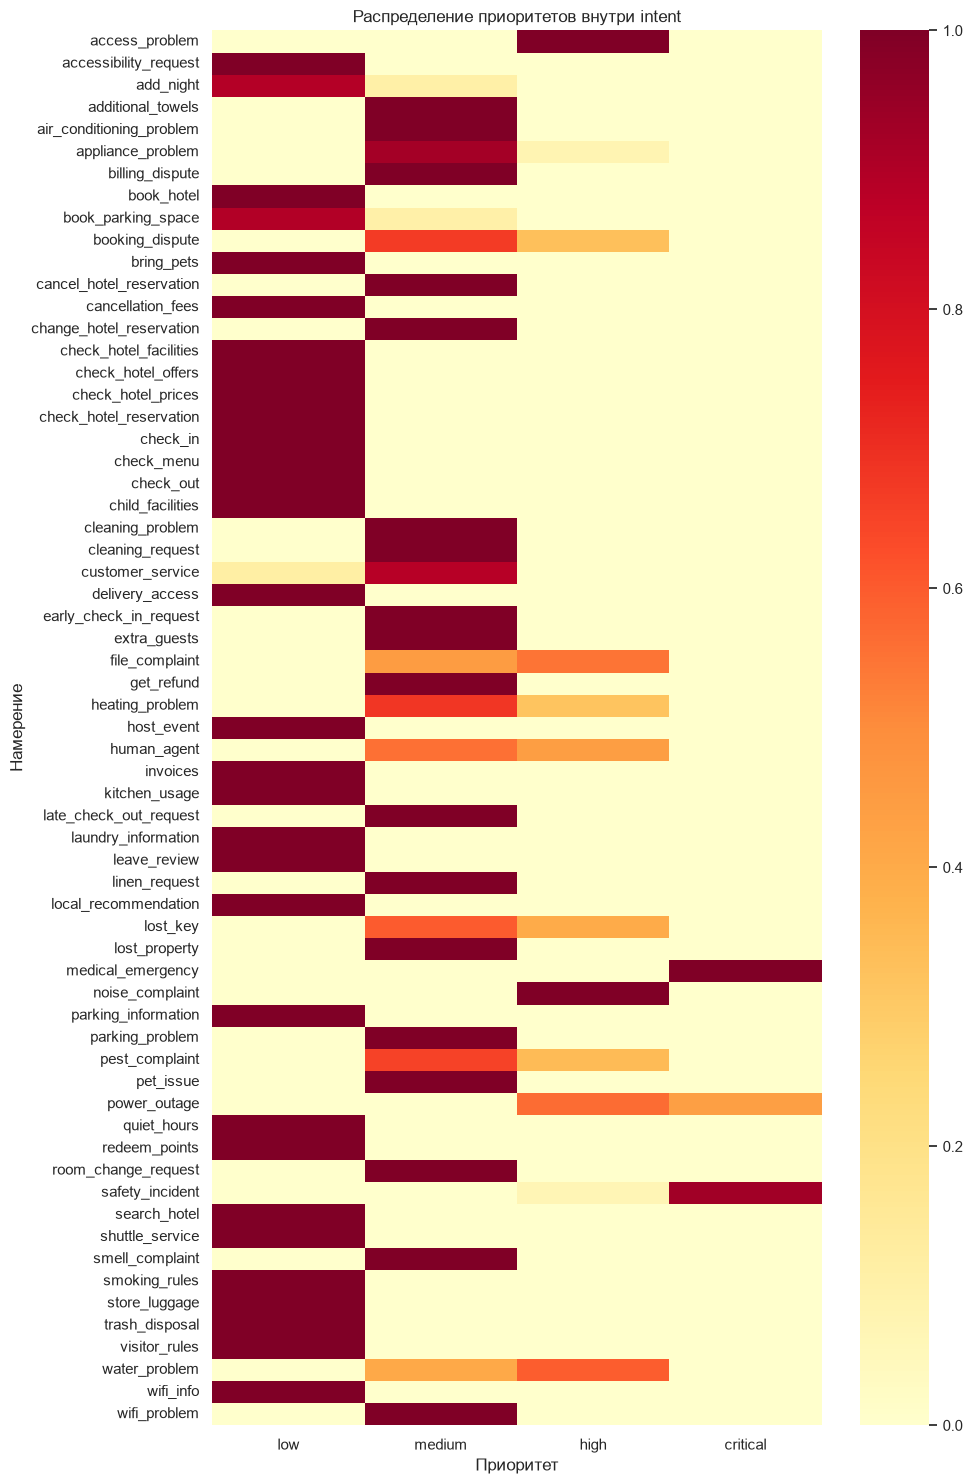

In [37]:
priority_by_intent = pd.crosstab(eda["intent"],eda["priority"],normalize="index").reindex(columns=PRIORITY_ORDER,fill_value=0)
fig, ax = plt.subplots(figsize=(10, 15))
sns.heatmap(priority_by_intent,cmap="YlOrRd",vmin=0,vmax=1,ax=ax)
ax.set_title("Распределение приоритетов внутри intent")
ax.set_xlabel("Приоритет")
ax.set_ylabel("Намерение")
plt.tight_layout()
plt.show()

Исходя из получившихся результатов анализа видно, что для 50 из 63 намерений, или 79,4% классов, представлен только один уровень приоритета. Оставшиеся 13 намерений содержат два уровня срочности.

Таким образом, вариативность приоритетов внутри большинства намерений крайне ограничена(результат согласуется с ранее установленной высокой ассоциацией между intent и priority — V Крамера составляет 0,8785)

С точки зрения ML это означает, что модель приоритизации может достичь высокой согласованности с существующей разметкой, преимущественно распознавая тип запроса. Однако есть и минусы у данного подхода, так как он не всегда позволит различать степень опасности конкретной ситуации. Например, техническая неисправность может иметь различную срочность в зависимости от того, препятствует ли она проживанию, создаёт ли риск безопасности и насколько быстро ситуация развивается.

### Анализ редкого критического класса

В задаче классификации приоритетов ошибки могут иметь различную практическую значимость.

Особенно важны случаи, когда обращение, требующее немедленного реагирования, ошибочно классифицируется как менее срочное.Поэтому необходимо отдельно исследовать представленность класса critical, его тематический состав и соотношение с другими уровнями приоритета.

Хотя общий анализ распределения приоритетов уже выполнен моим сокомандником, здесь акцент делается на последствиях дисбаланса для обучения и оценки ML-модели.

In [38]:
critical_df = eda.loc[eda["priority"] == "critical"].copy()
critical_count = len(critical_df)
critical_share = critical_count / len(eda)
critical_intents = (critical_df["intent"].value_counts().to_frame("Количество"))
print("Критических обращений:", critical_count)
print(f"Доля критического класса: {critical_share:.3%}")
display(critical_intents)
print("\nПримеры критических обращений:")
display(critical_df[["instruction","intent","needs_escalation"]].sample(n=min(12, len(critical_df)),random_state=RANDOM_STATE))

Критических обращений: 287
Доля критического класса: 0.820%


,Количество
intent,
safety_incident,124
medical_emergency,107
power_outage,56



Примеры критических обращений:


,instruction,intent,needs_escalation
25433,"Ребёнок обжёгся кипятком, срочно нужна помощь....",medical_emergency,1
33514,Нужна немедленная помощь. Дверь аварийного вых...,safety_incident,1
29706,С потолка течёт вода рядом с электропроводкой....,safety_incident,1
32058,Дверь аварийного выхода заблокирована. Это про...,safety_incident,1
32683,Нужна немедленная помощь. Человек без сознания...,medical_emergency,1
31448,Гость резко почувствовал сильное головокружени...,medical_emergency,1
28286,"Гостю стало плохо, он почти теряет сознание. В...",medical_emergency,1
27569,"Свет погас резко. В электрощитке слышно треск,...",power_outage,1
28766,Помогите быстро связаться с ответственными. У ...,medical_emergency,1
26198,Рядом есть другие гости. У пожилого родственни...,medical_emergency,1


Полученное распределение свидетельствует о тематической концентрации наиболее срочных запросов в ситуациях, связанных с безопасностью, медицинскими обстоятельствами и проблемы с техникой.

Одновременно наблюдается выраженный дисбаланс: класс critical существенно уступает по численности наиболее распространённым уровням приоритета. Следовательно жто приводит к подбору качественных метрик для оценки дальнейшей модели. Важно будет учесть, что классификатор может показывать высокую общую Accuracy, правильно обрабатывая многочисленные стандартные обращения, но при этом пропускать значительную часть критических ситуаций.

Поэтому для оценки модели приоритизации необходимо использовать не только Macro F1, но и отдельно рассчитывать Recall для класса critical, а также анализировать структуру ошибок.

## Часть 4 Предобработка данных для дальнейшего ML

### Очистка и нормализация текста

In [39]:
import re
import html
import unicodedata

def clean_guest_text(value):
    if pd.isna(value):
        return ""
    text = html.unescape(str(value))
    text = unicodedata.normalize("NFKC",text)
    text = text.replace("\u200b", "")
    text = text.replace("\ufeff", "")
    text = text.replace("\u00a0", " ")
    text = re.sub(r"\s+", " ", text)
    return text.strip()


def normalize_text_key(value):
    text = clean_guest_text(value)
    text = text.casefold().replace("ё", "е")
    text = re.sub(r"[^\w\s]", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

In [ ]:
# Создаём рабочую копию
prep = df.copy(deep=True)
prep["model_text"] = (prep["instruction"].map(clean_guest_text))
prep["text_key"] = (prep["model_text"].map(normalize_text_key))

# Приводим целевые переменные к корректным типам
for col in ["needs_escalation", "has_typos"]:
    prep[col] = pd.to_numeric(prep[col],errors="raise").astype("int8")

prep["intent"] = (prep["intent"].astype("string").str.strip())
prep["priority"] = (prep["priority"].astype("string").str.strip().str.lower())

# Проверка сохранения смысловых различий
assert (normalize_text_key("Не работает интернет")!= normalize_text_key("Работает интернет"))

assert prep["model_text"].str.len().gt(0).all()
assert prep["request_id"].is_unique
assert prep["intent"].notna().all()
assert prep["priority"].isin(PRIORITY_ORDER).all()

print("Исходных обращений:", len(df))
print("После очистки:", len(prep))

display(prep[["instruction", "model_text", "text_key"]].head(10))

Исходных обращений: 35000
После очистки: 35000


,instruction,model_text,text_key
0,"Чёрт возьми, не нахожу выставленные счета, пом...","Чёрт возьми, не нахожу выставленные счета, пом...",черт возьми не нахожу выставленные счета помог...
1,"Не нахожу выставленные счета, помогите. Где мн...","Не нахожу выставленные счета, помогите. Где мн...",не нахожу выставленные счета помогите где мне ...
2,Как скачать счета из личноо кабинета? Объяснит...,Как скачать счета из личноо кабинета? Объяснит...,как скачать счета из личноо кабинета объясните...
3,"Да что же это таке, подскажите, как получить к...","Да что же это таке, подскажите, как получить к...",да что же это таке подскажите как получить коп...
4,"Не нахожу выставленные счета, помогите. Что дл...","Не нахожу выставленные счета, помогите. Что дл...",не нахожу выставленные счета помогите что для ...
5,Где можно посмотреть мои счета за проживвание?...,Где можно посмотреть мои счета за проживвание?...,где можно посмотреть мои счета за проживвание ...
6,"Не нахожу выставленные счета, помогите. Можете...","Не нахожу выставленные счета, помогите. Можете...",не нахожу выставленные счета помогите можете п...
7,"Блин, мне нужно проверить счеат за проживание....","Блин, мне нужно проверить счеат за проживание....",блин мне нужно проверить счеат за проживание п...
8,"Не нахожу выставленные счета, помогите. Хотело...","Не нахожу выставленные счета, помогите. Хотело...",не нахожу выставленные счета помогите хотелось...
9,Как скачать счтеа из личного кабинета? Подскаж...,Как скачать счтеа из личного кабинета? Подскаж...,как скачать счтеа из личного кабинета подскажи...


### Формирование специализированных обучающих корпусов

In [41]:
# Анализ согласованности меток
label_groups = (prep.groupby("text_key").agg(n_intents=("intent", "nunique"),n_escalations=("needs_escalation", "nunique"),n_priorities=("priority", "nunique")))
# Добавляем индикаторы конфликтов
prep["intent_conflict"] = (prep["text_key"].map(label_groups["n_intents"]) > 1)
prep["escalation_conflict"] = (prep["text_key"].map(label_groups["n_escalations"]) > 1)
prep["priority_conflict"] = (prep["text_key"].map(label_groups["n_priorities"]) > 1)

# Корпус для Intent Classification
df_intent = (prep.loc[~prep["intent_conflict"]].sort_values(["text_key", "request_id"]).drop_duplicates("text_key").reset_index(drop=True).copy())
# Предварительный корпус для Escalation Classification
df_weak_escalation = (prep.loc[~prep["escalation_conflict"]].sort_values(["text_key", "request_id"]).drop_duplicates("text_key").reset_index(drop=True).copy())
# Предварительный корпус для Priority Classification
df_weak_priority = (prep.loc[~prep["priority_conflict"]].sort_values(["text_key", "request_id"]).drop_duplicates("text_key").reset_index(drop=True).copy())
approved_statuses = {"approved","verified","expert_verified"}

df_gold = prep.loc[prep["annotation_status"].isin(approved_statuses)].copy()

summary = pd.DataFrame({
    "Dataset": [
        "Полный очищенный корпус",
        "Intent Classification",
        "Weak Escalation",
        "Weak Priority",
        "Expert Verified"
    ],
    "Rows": [
        len(prep),
        len(df_intent),
        len(df_weak_escalation),
        len(df_weak_priority),
        len(df_gold)
    ]
})

display(summary)
assert df_intent["text_key"].is_unique
assert (df_intent["intent"].nunique()== prep["intent"].nunique())

,Dataset,Rows
0,Полный очищенный корпус,35000
1,Intent Classification,28800
2,Weak Escalation,28610
3,Weak Priority,28799
4,Expert Verified,0


In [42]:
from sklearn.model_selection import train_test_split

assert df_intent["scenario_group_id"].notna().all()
group_intent_count = (df_intent.groupby("scenario_group_id")["intent"].nunique())
assert group_intent_count.max() == 1
text_group_count = (prep.groupby("text_key")["scenario_group_id"].nunique())
assert text_group_count.max() == 1
groups = (df_intent.groupby("scenario_group_id").agg(intent=("intent", "first"),n_rows=("request_id", "size")).reset_index())
print("Всего сценарных групп:", len(groups))
print("Минимальное количество групп на intent:",groups["intent"].value_counts().min())

Всего сценарных групп: 902
Минимальное количество групп на intent: 12


In [43]:
train_groups, temp_groups = train_test_split(groups,test_size=0.30,stratify=groups["intent"],random_state=RANDOM_STATE)
val_groups, test_groups = train_test_split(temp_groups,test_size=0.50,stratify=temp_groups["intent"],random_state=RANDOM_STATE)

train_df = df_intent.loc[df_intent["scenario_group_id"].isin(train_groups["scenario_group_id"])].copy()
val_df = df_intent.loc[df_intent["scenario_group_id"].isin(val_groups["scenario_group_id"])].copy()

test_df = df_intent.loc[df_intent["scenario_group_id"].isin(test_groups["scenario_group_id"])].copy()

split_summary = pd.DataFrame({"Subset": ["Train", "Validation", "Test"],
                              "Rows": [len(train_df),len(val_df),len(test_df)],
                              "Intents": [
                                  train_df["intent"].nunique(),
                                  val_df["intent"].nunique(),
                                  test_df["intent"].nunique()],
                                  "Min examples per intent": [
                                      train_df["intent"].value_counts().min(),
                                      val_df["intent"].value_counts().min(),
                                      test_df["intent"].value_counts().min()]
})
display(split_summary)

,Subset,Rows,Intents,Min examples per intent
0,Train,20420,63,69
1,Validation,4436,63,17
2,Test,3944,63,13


In [ ]:
import joblib
from pathlib import Path

root = globals().get("PROJECT_ROOT",globals().get("BASE", Path.cwd()))
processed_dir = Path(root) / "data" / "processed"
processed_dir.mkdir(parents=True,exist_ok=True)

train_df.to_csv(processed_dir / "intent_train.csv",sep=";",index=False,encoding="utf-8-sig")
val_df.to_csv(processed_dir / "intent_val.csv",sep=";",index=False,encoding="utf-8-sig")
test_df.to_csv(processed_dir / "intent_test.csv",sep=";",index=False,encoding="utf-8-sig")